In [9]:
import os
import sys
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
import mne

ROOT = pathlib.Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUT_DIR = ROOT / 'out' / 'figs'
OUT_DIR.mkdir(parents=True, exist_ok=True)

from scripts import paper_style  # two-column paper style for every figure (sizes/font in scripts/paper_style.py)
from scripts.paper_style import (TEXT_W, TITLE_FONT, CAT_COLORS, DIV_CMAP, INK_PRIMARY, INK_SECONDARY,
                         clean_axes, enforce_font_sizes)
from scripts.dataset_manager import read_raw_dataset

mne.set_log_level('WARNING')

In [10]:
EPOCH_FILTERED = ROOT / 'data' / 'epoch_dataset_filtered'   # post-AutoReject (main Part-2 dataset)
RES_DIR = ROOT / 'out'                                # written by 17_feedback_and_significance_analysis.ipynb
PINCH_ID, NOPINCH_ID = "PinchLog", "NoPinchLog"
TOPO_TIMES = [-0.4, 0.0, 0.2]

# ---------------------------------------------------------------- colours (fixed paper palette)
C_PINCH, C_NO = CAT_COLORS[0], CAT_COLORS[1]   # same pairing as the ERP figures
C_ABSENT = "#9aa5b1"                           # feedback absent, as in the feedback-condition figure
MODEL_COLORS = CAT_COLORS[:3]                  # RF, EEGNet, Transformer in palette order
BAR_EDGE = dict(edgecolor=INK_PRIMARY, linewidth=0.5)

# ---------------------------------------------------------------- data, panel c
MODELS = {"RF": "RF", "EEGNet": "EEGNet", "Transformer": "Transf."}   # csv name -> tick label
loso = pd.read_csv(RES_DIR / "model_metrics_loso.csv").set_index("model").loc[list(MODELS)]
per_fold = pd.read_csv(RES_DIR / "per_fold_accuracy_loso.csv")
LOSO_MEAN = loso["accuracy_mean"].to_numpy()
CHANCE = loso["chance_mean"].iloc[0]
PER_SUBJECT = {m: per_fold.loc[per_fold["model"] == m, "acc"].to_numpy() for m in MODELS}

# EEGNet out-of-fold pinch recall with the feedback absent vs present, Fisher's exact p
# (same p as feedback_condition_accuracy.pdf in 17)
fb = pd.read_csv(RES_DIR / "feedback_condition_breakdown.csv").set_index("condition")
FEEDBACK = [  # (label, recall absent, recall present, p)
    (label, fb.loc[cond, "detection_rate_false"], fb.loc[cond, "detection_rate_true"],
     fb.loc[cond, "fisher_p_value"])
    for label, cond in [("FB\ndelayed", "feedbackIsDelayed"), ("virtual\nhand", "hasVirtualHand")]
]
print(loso[["accuracy_mean", "chance_mean"]], "\nsubjects per model:",
      {m: len(v) for m, v in PER_SUBJECT.items()})
print(FEEDBACK)

             accuracy_mean  chance_mean
model                                  
RF                0.635471     0.531375
EEGNet            0.700328     0.531375
Transformer       0.635031     0.531375 
subjects per model: {'RF': 19, 'EEGNet': 19, 'Transformer': 19}
[('FB\ndelayed', np.float64(0.6898971000935453), np.float64(0.6187050359712231), np.float64(0.0198179277680993)), ('virtual\nhand', np.float64(0.6618004866180048), np.float64(0.702451394759087), np.float64(0.0324119054535779))]


In [11]:
def get_signal():
    """Grand averages over all AutoReject-filtered epochs (same data and normalization as the
    ERP/topomap figures in 18_publication_figures): times, pinch and no-pinch ERP at C3 (µV),
    scalp-map info and {time: pinch topography (µV)}."""
    epochs_dict = read_raw_dataset(EPOCH_FILTERED)
    epochs = mne.concatenate_epochs([ep for sessions in epochs_dict.values() for ep in sessions.values()])
    epochs.apply_function(lambda x: (x - x.mean()), channel_wise=True)  # matches 13's own normalization
    md = epochs.metadata
    ev_p = epochs[((md["EventType"] == PINCH_ID) & (md["PinchType"] == "PINCH")).to_numpy()].average()
    ev_n = epochs[(md["EventType"] == NOPINCH_ID).to_numpy()].average()
    print(f"{len(epochs_dict)} participants; pinch n={ev_p.nave}, no pinch n={ev_n.nave}")

    c3 = ev_p.ch_names.index("C3")
    ev_topo = ev_p.copy().pick([c for c in ev_p.ch_names if c not in ("A1", "A2")])  # no mastoid refs
    topo = {tt: ev_topo.copy().crop(tt - .02, tt + .02).data.mean(1) * 1e6 for tt in TOPO_TIMES}
    return ev_p.times, ev_p.data[c3] * 1e6, ev_n.data[c3] * 1e6, ev_topo.info, topo


def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."


# ---------------------------------------------------------------- panel a
# white label boxes over the photo, each sized to its text: (text, (x, y), va) with the
# text's left edge at x and its top (va="top") or bottom (va="bottom") edge at y,
# as fractions of the image measured from the top-left corner
SETUP_LABELS = [
    ("DSI-24\n19 electrodes",  (0.04, 0.04), "top"),
    ("VR HMD +\neye tracking", (0.58, 0.04), "top"),
    ("in-headset view",        (0.04, 0.80), "bottom"),
]

def draw_setup(ax):
    img = mpimg.imread(ROOT / "assets" / "teaserSetupImage.jpg")
    ax.imshow(img, aspect="auto", interpolation="lanczos")
    ax.axis("off")
    for text, (x, y), va in SETUP_LABELS:
        ax.text(x, 1 - y, text, transform=ax.transAxes, ha="left", va=va,
                color=INK_PRIMARY, linespacing=1.15, zorder=4,
                bbox=dict(boxstyle="square,pad=0.35", facecolor="white", edgecolor="none"))


# ---------------------------------------------------------------- panel b
def draw_signal(fig, spec, t, pinch, nopinch, info, topo):
    gs = GridSpecFromSubplotSpec(2, 4, subplot_spec=spec, width_ratios=[1, 1, 1, 0.07],
                                 height_ratios=[1, 1.35], hspace=0.45, wspace=0.08)
    vlim = max(np.abs(v).max() for v in topo.values())
    im = None
    for i, (tt, data) in enumerate(topo.items()):
        a = fig.add_subplot(gs[0, i])
        im, _ = mne.viz.plot_topomap(data, info, axes=a, show=False, cmap=DIV_CMAP,
                                     vlim=(-vlim, vlim), contours=0, sensors=True)
        a.set_title(f"{tt:+.1f} s" if tt else "0 s (pinch)", pad=1)
    cax = fig.add_subplot(gs[0, 3])
    cb = fig.colorbar(im, cax=cax)
    tick = np.floor(vlim * 10) / 10  # largest 0.1 µV step inside the colour range
    cb.set_ticks([-tick, 0, tick], labels=[f"{-tick:g}", "0", f"{tick:g}"])
    cax.set_title("µV", pad=2)
    cb.outline.set_linewidth(0.4)

    a = fig.add_subplot(gs[1, :])
    a.axhline(0, color=INK_SECONDARY, linewidth=0.5, alpha=0.5)
    a.axvline(0, color=INK_SECONDARY, linewidth=0.6, linestyle=":")
    a.plot(t, nopinch, color=C_NO, label="No pinch")
    a.plot(t, pinch, color=C_PINCH, label="Pinch")
    a.set_xlim(t[0], t[-1])
    lo, hi = min(pinch.min(), nopinch.min()), max(pinch.max(), nopinch.max())
    a.set_ylim(lo - 0.35 * (hi - lo), hi + 0.45 * (hi - lo))  # room for the legend and the annotation
    a.set_xlabel("Time to pinch completion (s)")
    a.set_ylabel("C3 (µV)")
    a.legend(frameon=False, loc="upper left", handlelength=1.2, borderaxespad=0.1)
    # point at the pinch ERP's minimum around the pinch
    win = (t > -0.3) & (t < 0.2)
    i_min = np.flatnonzero(win)[np.argmin(pinch[win])]
    a.annotate("contralateral negativity", xy=(t[i_min], pinch[i_min]),
               xytext=(0.2, 0.04), textcoords="axes fraction",
               color=C_PINCH, va="bottom",
               arrowprops=dict(arrowstyle="->", lw=0.6, color=C_PINCH))
    clean_axes(a)
    return cax, cb


# ---------------------------------------------------------------- panel c
def draw_verdict(fig, spec):
    gs = GridSpecFromSubplotSpec(1, 2, subplot_spec=spec, width_ratios=[1.5, 1],
                                 wspace=0.5)
    ticks = [0.4, 0.5, 0.6, 0.7, 0.8]
    # accuracy
    a = fig.add_subplot(gs[0])
    rng = np.random.default_rng(1)
    for i, (m, mu, c) in enumerate(zip(MODELS, LOSO_MEAN, MODEL_COLORS)):
        a.bar(i, mu - 0.4, bottom=0.4, width=0.8, color=c, zorder=2, **BAR_EDGE)
        pts = PER_SUBJECT[m]
        a.scatter(i + rng.uniform(-0.17, 0.17, pts.size), pts, s=4, color=INK_PRIMARY,
                  alpha=0.55, lw=0, zorder=3)
        a.text(i, 0.815, f"{mu*100:.1f}%", ha="center")
    a.axhline(CHANCE, color=INK_PRIMARY, linewidth=0.6, linestyle="--", zorder=4)
    a.text(0, CHANCE - 0.006, "chance", ha="center", va="top", color="white", zorder=5)
    a.set_xticks(range(3)); a.set_xticklabels(MODELS.values())
    a.set_ylim(0.4, 0.88); a.set_yticks(ticks)
    a.set_yticklabels([f"{v*100:.0f}" for v in ticks])
    a.set_ylabel("LOSO accuracy (%)")
    a.set_xlim(-0.5, 2.5)
    a.yaxis.grid(True)
    a.set_axisbelow(True)
    clean_axes(a)

    # feedback effect
    b = fig.add_subplot(gs[1])
    w = 0.36
    for i, (lab, off, on, p) in enumerate(FEEDBACK):
        b.bar(i - w / 2, off - 0.4, bottom=0.4, width=w, color=C_ABSENT, zorder=2,
              label="Absent" if i == 0 else None, **BAR_EDGE)
        b.bar(i + w / 2, on - 0.4, bottom=0.4, width=w, color=C_PINCH, zorder=2,
              label="Present" if i == 0 else None, **BAR_EDGE)
        top = max(on, off)
        b.text(i, top + 0.03, stars(p), ha="center")
        b.plot([i - w / 2, i - w / 2, i + w / 2, i + w / 2],
               [top + 0.02, top + 0.03, top + 0.03, top + 0.02], color=INK_PRIMARY, lw=0.5)
    # overall recall (computed in 17_feedback_and_significance_analysis.ipynb)
    b.axhline(0.6817, color=INK_PRIMARY, linewidth=0.6, linestyle="--", zorder=4, label="Mean")
    b.set_xticks([0, 1]); b.set_xticklabels([f[0] for f in FEEDBACK])
    b.set_ylim(0.4, 0.88); b.set_yticks(ticks)
    b.set_yticklabels([f"{v*100:.0f}" for v in ticks])
    b.set_ylabel("EEGNet recall (%)")
    b.set_xlim(-0.55, 1.55)
    b.set_xlabel("Feedback")
    b.yaxis.grid(True)
    b.set_axisbelow(True)
    b.legend(frameon=False, loc="upper right", handlelength=0.9, bbox_to_anchor=(1.08, 1.06))
    clean_axes(b)
    return a, b

C:\Users\nicol\AppData\Local\Temp\ipykernel_36264\4293311594.py:6: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  epochs = mne.concatenate_epochs([ep for sessions in epochs_dict.values() for ep in sessions.values()])


19 participants; pinch n=2623, no pinch n=2903
saved C:\Users\nicol\github\VIBE\DataAnalysis\out\figs\teaser.pdf


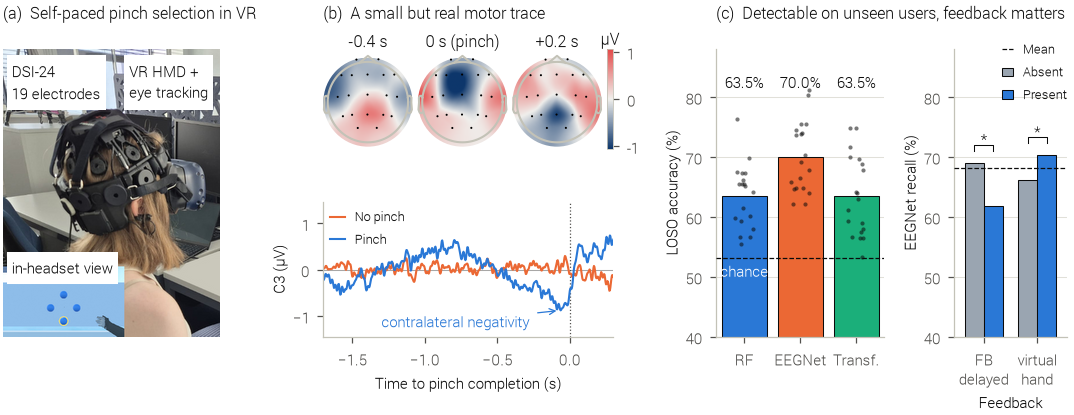

In [13]:
t, pinch, nopinch, info, topo = get_signal()

fig = plt.figure(figsize=(TEXT_W, 2.7))   # full page width (\textwidth)
gs = GridSpec(1, 3, figure=fig, width_ratios=[0.9, 1.2, 1.45],
              left=0.0, right=1.0, bottom=0.15, top=0.86, wspace=0.36)

draw_setup(fig.add_subplot(gs[0]))                                   # (a)
draw_signal(fig, gs[1], t, pinch, nopinch, info, topo)               # (b)
draw_verdict(fig, gs[2])                                             # (c)

# panel labels + headlines
heads = [("a", "Self-paced pinch selection in VR"),
         ("b", "A small but real motor trace"),
         ("c", "Detectable on unseen users, feedback matters")]
for spec, (l, h) in zip(gs, heads):
    x = spec.get_position(fig).x0
    fig.text(x, 0.975, f"({l})  {h}", fontsize=TITLE_FONT, va="top")

enforce_font_sizes(fig)
fig.savefig(OUT_DIR / "teaser.pdf")
print("saved", OUT_DIR / "teaser.pdf")